# Polish day-ahead prices and the merit order

This notebook is the first look at the data the model will forecast. It has two jobs. The first is to check that the stored prices are complete and sensible before anything is built on them. The second is to learn how the Polish price behaves, because every modelling choice that follows (which features to use, how to measure error, how much history to train on) should come from what the data shows, not from habit.

**Part 1** looks at the price on its own: its level over time, its shape within the day, and how often it goes negative. **Part 2**, added once `staging.py` exists, explains the price with residual load, which is the central idea of the project.

### Where this notebook sits in the project

`pl_dayahead.ingest.entsoe` downloads data from the ENTSO-E Transparency Platform and appends it to the `raw_entsoe` table in `data/pl_power.duckdb`, keeping every download. The `entsoe_latest` view returns the newest copy of each value. This notebook only reads from that view. It never writes to the database and never trains a model, so you can rerun it at any time without changing anything.

### How to run it

From the project root, run `uv run jupyter lab`, open this file and choose Run All. The three figures are also saved to `reports/figures/` so the README can show them.

## Background: what is being forecast

Every day at 12:00 Central European Time, the European day-ahead auction closes. It is called Single Day-Ahead Coupling (SDAC). Buyers and sellers in every bidding zone submit bids for each period of the next day, and one algorithm matches them across the continent while respecting the limits of the cross-border power lines. The result is one clearing price per bidding zone per period. Poland is a single bidding zone, and its exchange is TGE.

Until 30 September 2025 a period was one hour, so each day had 24 prices. From delivery on 1 October 2025 a period is 15 minutes, so each day has 96 prices (92 or 100 on the days the clocks change).

The price is set by the **merit order**. Generators offer at roughly their marginal cost, which is the cost of producing one more MWh: close to zero for wind and solar, higher for lignite and hard coal, higher again for gas. The offers are stacked from cheapest to most expensive, and the price is the offer of the last plant needed to meet demand. Every plant that runs receives that same price. This is why the price can jump: once demand passes the point where the cheap plants are all running, the next plant in the stack may cost much more.

Prices here are in EUR/MWh because SDAC clears in euros. TGE also publishes them in PLN, which is the same result converted.

In [1]:
# matplotlib draws the charts; mdates formats the dates on the x axis.
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# numpy does the numerical work; pandas holds the data as tables (DataFrames) and does
# the averaging and reshaping.
import numpy as np
import pandas as pd

# Builds a colour scale from a list of colours, used by the heatmap in chart 2.
from matplotlib.colors import LinearSegmentedColormap

# The project's own code, installed by uv from src/pl_dayahead.
from pl_dayahead import store  # opens the DuckDB database
from pl_dayahead.config import PROJECT_ROOT  # the repo folder, used to find reports/figures
from pl_dayahead.timeutils import LOCAL_TZ, missing_intervals  # Warsaw time zone and the gap check

## Step 1: load hourly prices

The model forecasts **hourly** prices, so the 15-minute prices from October 2025 onward are averaged into hours. This keeps one consistent target across the whole history, from January 2023 to today. The average of the four quarter-hour prices is also how the exchanges define their own 60-minute price index ([EPEX SPOT](https://epexspot.com/de/node/4164)), so the hourly series means the same thing before and after the change.

The averaging happens in SQL inside DuckDB, where the data already lives. Only the result, about 33,000 rows, comes into pandas.

The query also counts how many values went into each hour. This matters because an average hides missing data: an hour with only three of its four quarter-hour prices still produces a normal-looking price. The count lets the next step catch that.

In [2]:
con = store.connect()

# The query returns one row per hour:
#   date_trunc('hour', ts_utc) rounds each timestamp down to the start of its hour, so
#     10:00, 10:15, 10:30 and 10:45 all become 10:00. Before October 2025 the timestamps
#     are already on the hour, so nothing changes for them.
#   avg(value) is the hourly price: the mean of the four 15-minute prices, or the single
#     hourly price before October 2025.
#   count(*) is how many values went into the hour (1 or 4), checked in step 2.
# Timestamps stay in UTC. UTC has no clock changes, so every hour exists exactly once.
hourly = con.sql('''
    SELECT date_trunc('hour', ts_utc) AS hour_utc,
           avg(value)                 AS price,
           count(*)                   AS n_values
    FROM entsoe_latest
    WHERE series = 'price_da'
    GROUP BY 1
    ORDER BY 1
''').df().rename(columns={'hour_utc': 'ts_utc'})

# DuckDB allows only one process at a time to have the file open for writing. Closing the
# connection lets the ingest script run while this notebook is still open.
con.close()

hourly.head()

,ts_utc,price,n_values
0,2022-12-31 23:00:00+00:00,18.09,1
1,2023-01-01 00:00:00+00:00,5.75,1
2,2023-01-01 01:00:00+00:00,5.27,1
3,2023-01-01 02:00:00+00:00,5.74,1
4,2023-01-01 03:00:00+00:00,5.22,1


## Step 2: check the data before using it

First, each UTC hour gets its Warsaw local time and its delivery day. The database stores UTC because UTC has no clock changes, but the market, electricity demand and people's routines all follow the Warsaw clock, so charts and features use local time. A delivery day runs from local midnight to local midnight, which means it has 23 hours on the last Sunday of March and 25 on the last Sunday of October.

Then come two checks. `missing_intervals` lists every hour between the first and last delivery day that has no price at all. The `n_values` check finds hours built from two or three quarter-hour prices instead of four. Both should print zero: the ingest already confirmed the data is complete, and checking again here costs nothing and catches anything that has gone wrong since.

The last line prints summary statistics, which are a first description of the price. The minimum shows how negative prices get, the maximum how high spikes go, and the gap between the mean and the median (the 50% row) shows how much the spikes pull the average up. A mean well above the median means a few very high prices, which is typical of electricity.

In [3]:
# Convert each UTC hour to Warsaw time. On the October clock change, local 02:00 appears
# twice; in UTC these are two different hours, so nothing is lost or merged.
hourly['local'] = hourly['ts_utc'].dt.tz_convert(LOCAL_TZ)

# The delivery day is the local calendar date, stored as midnight of that date so that
# pandas can place it on a time axis.
hourly['day'] = pd.to_datetime(hourly['local'].dt.date)

gaps = missing_intervals(hourly['ts_utc'], 'h')  # hours with no price at all
partial = hourly[~hourly['n_values'].isin([1, 4])]  # hours with only 2 or 3 quarter-hour prices
print(f"{len(hourly):,} hours, delivery days {hourly['day'].min():%Y-%m-%d} to {hourly['day'].max():%Y-%m-%d}")
print(f"{len(gaps)} missing hours; {len(partial)} hours built from an incomplete set of 15-minute prices")

# Summary statistics of the hourly price, in EUR/MWh.
hourly['price'].describe().round(1)

33,047 hours, delivery days 2023-01-01 to 2026-10-08
0 missing hours; 0 hours built from an incomplete set of 15-minute prices


count    33047.0
mean       107.1
std         52.2
min       -469.2
25%         85.0
50%        105.7
75%        130.1
max        663.2
Name: price, dtype: float64

In [4]:
# Chart styling, shared by all three charts. Nothing here touches the data: it only sets
# colours, fonts and gridlines so the figures look consistent in the README.
# The blue and the greys come from a palette tested for colour-blind readability.
INK, INK_2, MUTED = '#0b0b0b', '#52514e', '#898781'  # text: primary, secondary, muted
GRID, BASELINE, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'  # gridlines, axis line, background
BLUE = '#2a78d6'  # the one colour that carries data
BLUE_RAMP = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']  # light = low, dark = high

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'sans-serif', 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'axes.edgecolor': BASELINE, 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True,  # light horizontal gridlines behind the data
    'grid.color': GRID, 'grid.linewidth': 0.6,
    'legend.frameon': False,
})
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Chart 1: the price level

This chart shows the average price of each delivery day. That number is the day's **baseload price**: the price of delivering 1 MW in every hour of the day, which is how much of the market is quoted and traded.

Daily prices are noisy, so a 30-day rolling average is drawn on top. The rolling average at any date is the mean of the 30 daily prices up to and including that date, so it moves smoothly and shows the trend. It only starts once 20 days of history exist, which is why the blue line begins slightly after the grey one.

**What to look for.** Does the level stay roughly constant across the years, or does it drift? Are spikes single days, or do they last for weeks? Is there a seasonal pattern, and is it the same every year?

**Why it matters for the model.** Coal, gas and carbon prices move the whole level up and down, and v1 of the model does not see them directly. If the level drifts, a model trained on all of history at once would carry an outdated level into the present. That is why the backtest retrains every month on only the latest 365 days, and why yesterday's and last week's prices are features: they tell the model what the current level is.

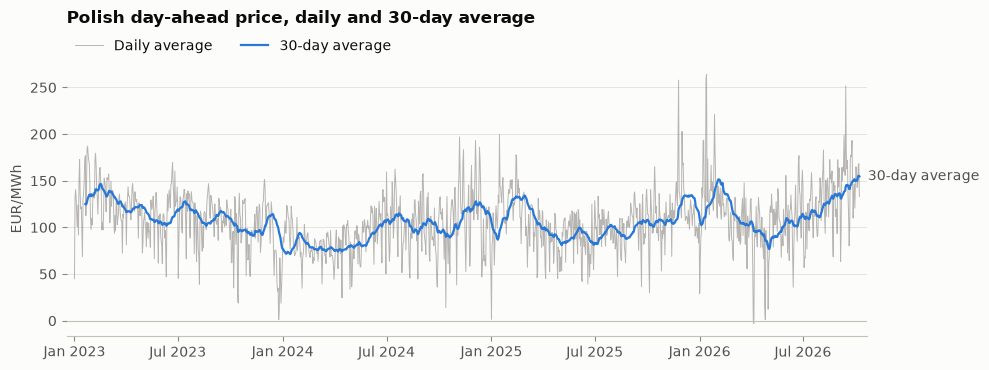

In [5]:
# Mean of all hourly prices in each delivery day: the baseload price.
daily = hourly.groupby('day')['price'].mean()

# 30-day rolling mean of the daily prices; empty until 20 days of history exist.
trend = daily.rolling(30, min_periods=20).mean()

fig, ax = plt.subplots(figsize=(10, 3.8))  # one chart, 10 x 3.8 inches

# Daily prices in faint grey as background, the trend in blue as the line to read.
ax.plot(daily.index, daily, color=MUTED, lw=0.7, alpha=0.6, label='Daily average')
ax.plot(trend.index, trend, color=BLUE, lw=1.6, label='30-day average')

# Draw a zero line only if some day averaged below zero.
if daily.min() < 0:
    ax.axhline(0, color=BASELINE, lw=0.8)

# Name the blue line at its end, so the reader does not have to look up the legend.
ax.annotate('30-day average', xy=(trend.index[-1], trend.iloc[-1]), xytext=(6, 0),
            textcoords='offset points', va='center', color=INK_2)

# One date label every January and July, written as "Jan 2023".
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

ax.set_title('Polish day-ahead price, daily and 30-day average', pad=28)
ax.set_ylabel('EUR/MWh')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)  # legend in a row under the title
ax.margins(x=0.01)
fig.tight_layout()
fig.savefig(FIG_DIR / 'price_level.png', dpi=150)  # saved for the README

## Chart 2: the shape of the day

This is a heatmap. Each column is one delivery day of the last 12 months, each row is one hour of the day in Warsaw time, and each cell is coloured by that hour's price: the darker the blue, the more expensive. Reading across a row shows how one hour's price changes through the year. Reading down a column shows the shape of a single day.

The colour scale is cut at the 2nd and 98th percentiles of the price. Without that, a handful of extreme hours would claim most of the colour range and every ordinary day would look the same. Prices beyond the cut take the end colours, which the pointed ends of the colour bar indicate. One empty cell each spring is the hour skipped when the clocks go forward.

**What to look for, and why each pattern exists.** Each pattern has a physical cause, and being able to name the cause is what an interviewer will test.

*Midday trough in spring and summer.* Poland had about 27 GW of solar capacity by mid-2026 ([Wikipedia](https://en.wikipedia.org/wiki/Solar_power_in_Poland)), a large share of it on household rooftops. Around noon on a sunny day solar covers a large part of demand, so the expensive plants at the top of the merit order are not needed and the price falls, sometimes below zero.

*Evening peak.* Solar output falls away in the late afternoon while demand is still high, so coal and gas plants have to ramp up and the most expensive of them set the price.

*Night.* Demand is at its lowest, but coal plants are slow and costly to switch off and on again, so many keep running through the night and the price sits in the middle of its range.

*Winter.* With little solar, the day's shape is driven by demand alone, which usually gives a morning and an evening peak.

**Why it matters for the model.** The hour of the day matters, and so does how it interacts with solar: solar only lowers the price around midday. A linear model handles the hour through separate hour features but cannot easily learn that interaction, which is the main reason gradient boosting is included as a comparison.

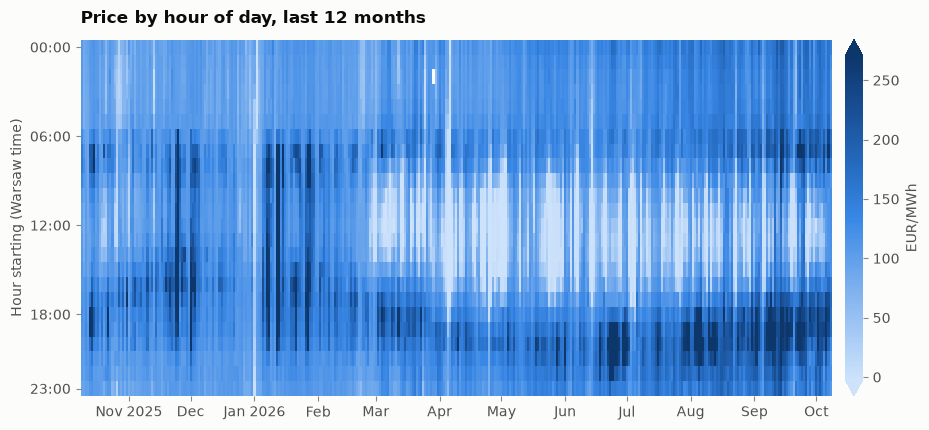

In [6]:
# Keep the last 365 delivery days.
last_day = hourly['day'].max()
recent = hourly[hourly['day'] > last_day - pd.Timedelta(days=365)]

# Reshape into a grid: one row per local hour (0 to 23), one column per delivery day.
# On the October clock change hour 2 occurs twice, so the two values are averaged
# (aggfunc='mean'); on the March change hour 2 does not exist and stays empty.
grid = recent.pivot_table(index=recent['local'].dt.hour, columns='day', values='price', aggfunc='mean')

# Colour limits: the 2nd and 98th percentiles of the price over these 12 months.
lo, hi = recent['price'].quantile([0.02, 0.98])

# Colour scale from light blue (cheap) to dark blue (expensive); empty cells get the background colour.
cmap = LinearSegmentedColormap.from_list('price', BLUE_RAMP)
cmap.set_bad(SURFACE)

fig, ax = plt.subplots(figsize=(10, 4.4))
# imshow draws the grid as an image, one cell per value; aspect='auto' stretches it to the figure.
im = ax.imshow(grid.to_numpy(), aspect='auto', cmap=cmap, vmin=lo, vmax=hi, interpolation='nearest')

# A label on the first day of each month; the year is added in January and on the first label.
months = [i for i, d in enumerate(grid.columns) if d.day == 1]
ax.set_xticks(months, [grid.columns[i].strftime('%b %Y') if grid.columns[i].month == 1 or i == months[0]
                       else grid.columns[i].strftime('%b') for i in months])
ax.set_yticks([0, 6, 12, 18, 23], ['00:00', '06:00', '12:00', '18:00', '23:00'])
ax.grid(False)
ax.spines['bottom'].set_visible(False)
ax.set_title('Price by hour of day, last 12 months')
ax.set_ylabel('Hour starting (Warsaw time)')

# Colour bar: the key from colour to EUR/MWh. extend='both' adds the pointed ends that mark clipped values.
cbar = fig.colorbar(im, ax=ax, extend='both', pad=0.015)
cbar.set_label('EUR/MWh')
cbar.outline.set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'price_by_hour.png', dpi=150)

## Chart 3: negative prices

This chart counts, for each month, the hours whose price was below zero. Since October 2025 an hour counts if the average of its four quarter-hour prices is below zero, so a single negative quarter-hour inside an otherwise positive hour is not counted.

**Why prices go negative.** A negative price means sellers are paying buyers to take power. It happens when supply cannot be reduced quickly or cheaply enough to match demand. Some plants are costly to turn down: coal units have a minimum stable output, and combined heat and power plants must keep running to supply district heating. Some renewable plants earn revenue that does not depend on the market price, so they have less reason to stop. When these together produce more than the country uses and can export, the price falls below zero. The grid operator PSE also orders renewable plants to cut output when the system cannot absorb it: 1,376 GWh in 2025, mostly solar around midday ([Gramwzielone.pl](https://www.gramwzielone.pl/?p=20369542)). Negative prices and these cuts are two signs of the same surplus.

**What to look for.** Which months negative prices appear in, and whether the count grows from year to year as solar capacity grows. The current month is incomplete, so its bar is not comparable yet.

**Why it matters for the model.** Negative prices rule out some common shortcuts, such as modelling the logarithm of the price, which does not exist below zero. They are also where a forecast is most likely to fail badly, so the worst days in the post-mortem will probably include some of them. Error is measured as mean absolute error partly because a squared-error measure would let a few such hours dominate the result.

,mean_price,negative_hours
month,,
2023-01,132.5,0
2023-02,136.8,0
2023-03,120.4,0
2023-04,122.1,0
2023-05,105.7,0
2023-06,118.2,5
2023-07,115.8,0
2023-08,107.1,0
2023-09,109.8,0


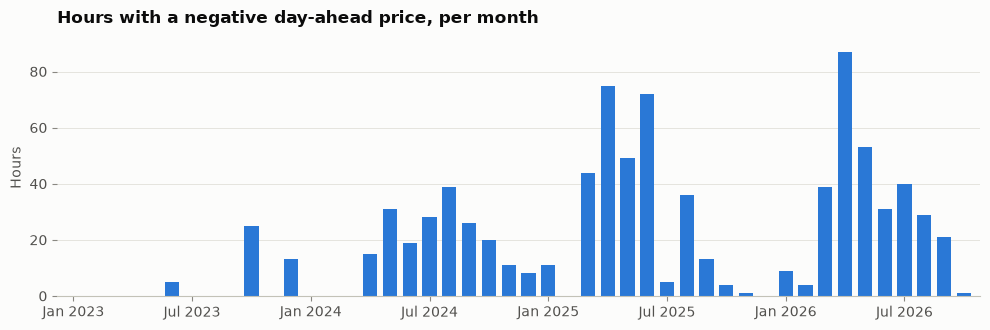

In [7]:
# One row per month: the average price and the number of negative hours.
monthly = (
    hourly.assign(month=hourly['local'].dt.strftime('%Y-%m'))  # local month as text, e.g. '2025-06'
    .groupby('month')
    .agg(mean_price=('price', 'mean'), negative_hours=('price', lambda s: int((s < 0).sum())))
)

fig, ax = plt.subplots(figsize=(10, 3.4))
x = range(len(monthly))  # bar positions 0, 1, 2, ...
ax.bar(x, monthly['negative_hours'], width=0.72, color=BLUE)

# Label January and July only, so the labels do not overlap.
ticks = [i for i, m in enumerate(monthly.index) if m.endswith(('-01', '-07'))]
ax.set_xticks(ticks, [pd.Period(monthly.index[i]).strftime('%b %Y') for i in ticks])
ax.set_title('Hours with a negative day-ahead price, per month')
ax.set_ylabel('Hours')
ax.margins(x=0.01)
fig.tight_layout()
fig.savefig(FIG_DIR / 'negative_hours.png', dpi=150)

# The same numbers as a table, plus each month's average price, for exact values.
monthly.round(1)

### When negative prices happen

The chart shows how many negative hours each month had, not when in the day they fall. This cell checks the two explanations suggested by the chart: solar surplus at midday in spring and summer, and wind with low demand at night or on weekends in the colder months.

It prints the exact yearly totals, the share of negative hours that fall on a weekend, and a table with one row per calendar month and one column per hour of the day, where each cell counts negative hours. If the solar explanation holds, the April to August rows concentrate between about 10:00 and 15:00. If wind and low demand drive the winter cases, the October to February rows spread across the night. Weekends are 2 of 7 days, about 29% of all hours, so a weekend share well above that means low demand matters as much as high supply.

In [8]:
neg = hourly[hourly['price'] < 0]

# Exact yearly totals (the index of `monthly` is 'YYYY-MM', so its first 4 characters are the year).
print(monthly.groupby(monthly.index.str[:4])['negative_hours'].sum())

if len(neg):
    weekend = (neg['local'].dt.dayofweek >= 5).mean()  # dayofweek: Monday = 0, Saturday = 5, Sunday = 6
    print(f"{weekend:.0%} of negative hours fall on a weekend (weekends are 29% of all hours)")

# Count of negative hours by calendar month (rows) and local hour of the day (columns).
pd.crosstab(neg['local'].dt.month.rename('month'), neg['local'].dt.hour.rename('hour'))

month
2023     43
2024    197
2025    310
2026    314
Name: negative_hours, dtype: int64
61% of negative hours fall on a weekend (weekends are 29% of all hours)


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
month,,,,,,,,,,,,,,,,,,
1,2,2,2,2,1,1,0,0,2,2,2,2,1,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0
3,0,0,0,0,0,0,0,0,2,6,13,17,20,17,7,1,0,0
4,1,0,0,0,0,1,1,2,2,4,13,23,30,33,28,25,11,3
5,0,0,0,0,0,0,0,0,1,5,14,20,23,26,23,14,7,0
6,0,0,0,0,0,0,0,0,1,8,10,18,26,21,20,12,9,2
7,0,0,0,0,0,0,0,0,0,2,7,11,13,12,13,9,3,3
8,0,0,0,0,0,0,1,1,1,5,9,13,17,21,19,11,5,1
9,0,0,0,0,0,0,0,0,0,0,4,10,14,17,12,3,0,0


## What I see

Write down what the three charts show before going further. These notes become the data section of the README and your answer when an interviewer asks what drives the Polish price.

A useful note names a pattern, puts a number on it and gives a cause. For example, the shape of a good note on chart 2 is: in which months the midday price falls below the evening price, by roughly how many EUR/MWh, and why. Read the numbers off the charts and the table above rather than guessing.

- Price level:
- Daily shape:
- Negative prices:
- Surprises or questions:

# Part 2: price against residual load

Part 1 described the price. Part 2 tests the explanation behind it.

**Residual load** is forecast demand minus forecast wind and solar output. Wind and solar have almost no marginal cost, so they are used first whenever they are available. Whatever demand is left over has to be met by coal, gas and other controllable plants, and that leftover decides how far up the merit order the market has to go. If the merit order explains the Polish price, the price should rise with residual load: slowly while cheap coal plants have spare capacity, then steeply once the expensive gas plants and peakers are needed.

Part 2 does three things. Step 3 checks that residual load is calculated correctly, because rooftop solar can be counted twice. Step 4 draws price against residual load, which is the central chart of the project. Step 5 measures how much better residual load explains the price than demand on its own.

Everything here reads the `hourly` table that `staging.py` builds, so run `uv run python -m pl_dayahead.staging` first if the data has changed.

In [9]:
con = store.connect()
staged = con.sql('SELECT * FROM hourly ORDER BY ts_utc').df()
con.close()

# Calendar columns in Warsaw time, used to select seasons, weekdays and hours below.
staged['local'] = staged['ts_utc'].dt.tz_convert(LOCAL_TZ)
staged['year'] = staged['local'].dt.year
staged['month'] = staged['local'].dt.month
staged['hour'] = staged['local'].dt.hour
staged['weekday'] = staged['local'].dt.dayofweek  # Monday = 0

GW = 1000  # the forecasts are in MW; the charts show GW (1 GW = 1,000 MW)

# Summary of each series in MW (price in EUR/MWh).
staged[['price', 'load_fcst', 'solar_fcst', 'wind_fcst', 'residual_load_fcst']].describe().round(0)

,price,load_fcst,solar_fcst,wind_fcst,residual_load_fcst
count,33047.0,33047.0,33047.0,33047.0,33047.0
mean,107.0,18729.0,2227.0,2722.0,13780.0
std,52.0,3245.0,3293.0,2103.0,4500.0
min,-469.0,10400.0,0.0,53.0,-4590.0
25%,85.0,16072.0,0.0,1039.0,10924.0
50%,106.0,18925.0,152.0,2134.0,13814.0
75%,130.0,21025.0,3712.0,3971.0,16808.0
max,663.0,27503.0,15699.0,9526.0,26110.0


## Step 3: is rooftop solar counted twice?

Poland's solar comes in two kinds. Solar farms are metered and report their output to the grid operator. Rooftop panels on homes and small businesses (micro-installations up to 50 kW) are not metered in real time, and in February 2025 they made up more than half of the installed capacity, about 12.2 GW out of 21.8 GW ([Wikipedia](https://en.wikipedia.org/wiki/Solar_power_in_Poland)). Rooftop power is used first inside the building, so on a sunny day the grid sees less demand.

That creates a trap. The load forecast may describe total consumption (gross) or only what the grid has to supply after rooftop output (net). The solar forecast may cover all panels or only the metered farms. Residual load is right in two of the four combinations:

- Gross load and all solar: correct, rooftop output is subtracted once.
- Net load and farms-only solar: correct, rooftop output was already taken out of the load.
- Net load and all solar: rooftop output is subtracted twice, so residual load is too low around midday.
- Gross load and farms-only solar: rooftop output is never subtracted, so residual load is too high around midday.

ENTSO-E's definitions do not settle this for Poland, so the data has to. Two tests answer the two questions.

**Test A: what does the solar forecast cover?** A whole national fleet rarely produces more than about 60 to 70% of its installed capacity at the same moment: panels face different directions, heat lowers their output, and some regions are always cloudy. If the solar forecast's peak reaches roughly 55% or more of total installed capacity, it must include rooftop panels. If it peaks near 30%, it covers only the farms, which were a little under half of the capacity.

The capacity figures below are year-end values (31 May for 2026). Summer peaks happen before year-end, when less capacity was installed, so the ratio is slightly understated, which makes the test conservative.

In [10]:
# Installed solar capacity in GW: end of year, and 31 May for 2026.
# Source: Wikipedia, Solar power in Poland. The yearly table there names no primary source,
# so these are approximate; they only need to be good enough to tell 30% from 60%.
CAPACITY_GW = {2023: 15.9, 2024: 21.7, 2025: 25.4, 2026: 26.9}

peaks = staged.groupby('year')['solar_fcst'].agg(
    peak='max',                              # the single highest hour
    p995=lambda s: s.quantile(0.995),        # a high value that one odd hour cannot set
).div(GW)
peaks['capacity_gw'] = pd.Series(CAPACITY_GW)
peaks['peak_share'] = peaks['peak'] / peaks['capacity_gw']
peaks.round(2)

,peak,p995,capacity_gw,peak_share
year,,,,
2023,9.85,9.03,15.9,0.62
2024,12.59,11.20,21.7,0.58
2025,13.90,11.72,25.4,0.55
2026,15.70,14.18,26.9,0.58


**Test B: what does the load forecast cover?** Take summer weekdays at the hour starting 12:00, when solar output is near its daily maximum, and compare days with a lot of solar to days with little. If the load forecast is net of rooftop output, sunnier middays show lower load, so load falls as solar rises: the fitted slope is clearly negative. If the load forecast is gross, the weather should barely move midday load and the slope is close to zero.

One effect works against the test. Sunny summer days tend to be hot, and air conditioning raises demand, which pushes the slope up towards zero. A clearly negative slope is therefore strong evidence of a net load forecast, while a slope near zero is weaker evidence the other way.

Each panel is one summer. Each dot is one weekday, and the line is a straight-line fit whose slope is shown in the panel title: MW of load per MW of solar.

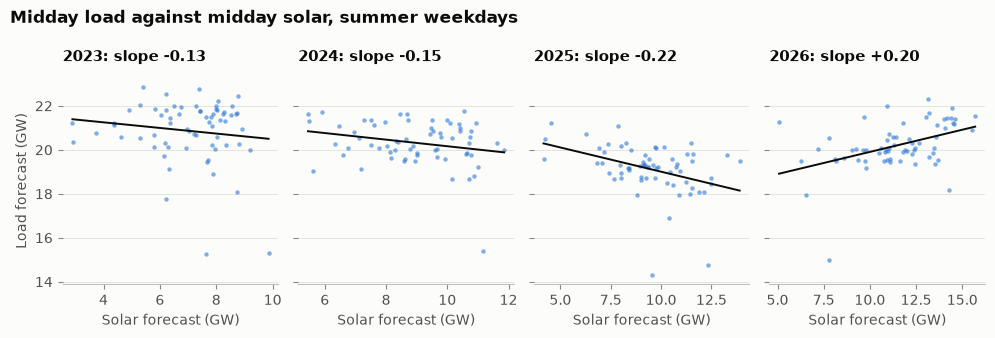

In [11]:
# Summer weekdays (June to August, Monday to Friday), hour starting 12:00 Warsaw time.
midday = staged[staged['month'].isin([6, 7, 8]) & (staged['weekday'] < 5) & (staged['hour'] == 12)]
midday = midday.dropna(subset=['solar_fcst', 'load_fcst'])
years = sorted(midday['year'].unique())

fig, axes = plt.subplots(1, len(years), figsize=(10, 3.4), sharey=True)
for ax, year in zip(np.atleast_1d(axes), years):
    d = midday[midday['year'] == year]
    x, y = d['solar_fcst'] / GW, d['load_fcst'] / GW
    slope, intercept = np.polyfit(x, y, 1)  # least-squares straight line: y = slope * x + intercept
    ax.scatter(x, y, s=10, color=BLUE, alpha=0.6, linewidths=0)
    xs = np.linspace(x.min(), x.max(), 2)
    ax.plot(xs, slope * xs + intercept, color=INK, lw=1.4)
    ax.set_title(f'{year}: slope {slope:+.2f}', fontsize=10.5)
    ax.set_xlabel('Solar forecast (GW)')
np.atleast_1d(axes)[0].set_ylabel('Load forecast (GW)')
fig.suptitle('Midday load against midday solar, summer weekdays', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'rooftop_check.png', dpi=150)

**Reading the two tests together.** Test A tells you whether the solar forecast includes rooftop panels, and Test B tells you whether the load forecast already has them taken out. Find your combination in the list at the top of this step.

If rooftop output turns out to be counted twice, the model is still safe: it uses load, wind and solar as separate features as well as residual load, so the regression can learn how much weight solar really deserves. What changes is how you read the chart in step 4 and the residual-load coefficient, and the finding goes into the README's limitations, together with the size of the effect.

## Step 4: the merit order in the data

Each dot is one hour: residual load on the horizontal axis and the price on the vertical axis. The dark line is the median price of all hours in each 1 GW band of residual load, drawn only where a band holds at least 30 hours. The median is used instead of the mean because a few extreme hours would drag a mean around. The line is the merit order as the market actually priced it.

There is one panel per year because the cost of the plants at the margin changes from year to year with coal, gas and carbon prices. The shape of the curve should be similar in every year, while its height moves. The price axis is cut at the 0.5th and 99.5th percentiles so the extreme hours don't flatten everything else. 2026 is a partial year.

**What to look for.** Does the price rise with residual load? Is the curve flat in the middle and steeper at the right-hand end, where the expensive plants are needed? What happens at the left-hand end, where wind and solar cover almost all demand: is that where the negative prices sit? And how much do prices scatter around the line at a given residual load? That scatter is what the forecast will get wrong, and the post-mortem will explain the biggest misses.

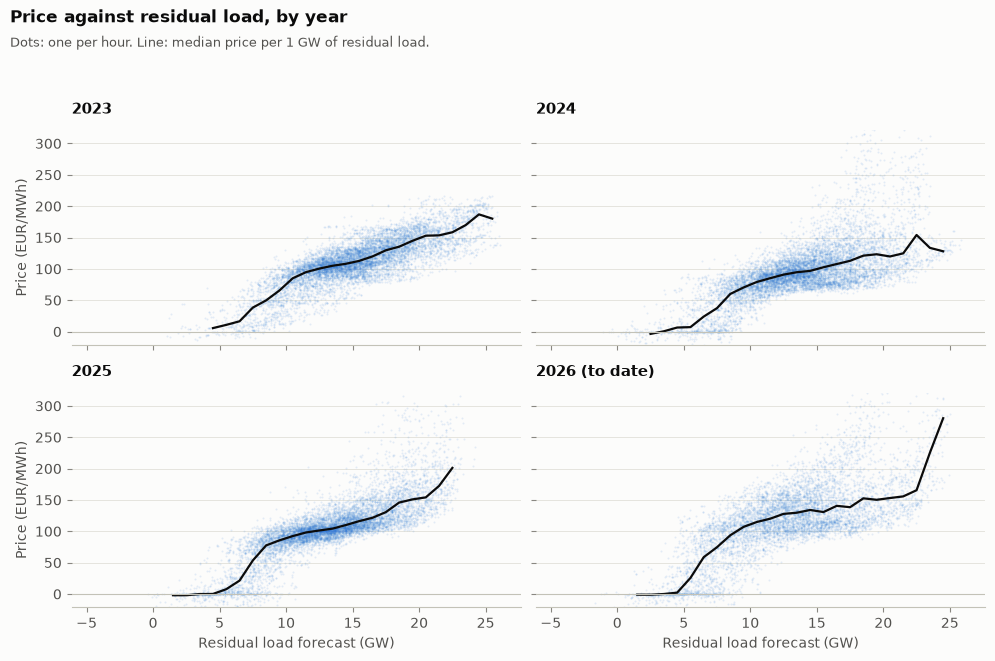

In [12]:
data = staged.dropna(subset=['price', 'residual_load_fcst'])
lo, hi = data['price'].quantile([0.005, 0.995])  # price axis limits
x_all = data['residual_load_fcst'] / GW
bins = np.arange(np.floor(x_all.min()), np.ceil(x_all.max()) + 1, 1.0)  # 1 GW bands

years = sorted(data['year'].unique())
ncols = 2
nrows = int(np.ceil(len(years) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 3.3 * nrows), sharex=True, sharey=True)
for ax, year in zip(axes.flat, years):
    d = data[data['year'] == year]
    x = d['residual_load_fcst'] / GW
    # rasterized=True stores the thousands of dots as an image, which keeps the saved file small.
    ax.scatter(x, d['price'], s=2, color=BLUE, alpha=0.12, linewidths=0, rasterized=True)

    # Median price per 1 GW band, only where the band has at least 30 hours.
    band = pd.cut(x, bins)
    per_band = d.groupby(band, observed=True)['price'].agg(['median', 'size'])
    per_band = per_band[per_band['size'] >= 30]
    ax.plot([b.mid for b in per_band.index], per_band['median'], color=INK, lw=1.6)

    ax.set_title(str(year) + (' (to date)' if year == years[-1] else ''), fontsize=10.5)
    ax.axhline(0, color=BASELINE, lw=0.8)
for ax in axes.flat[len(years):]:
    ax.set_visible(False)  # hide any unused panel
for ax in axes[-1]:
    ax.set_xlabel('Residual load forecast (GW)')
for ax in axes[:, 0]:
    ax.set_ylabel('Price (EUR/MWh)')
axes.flat[0].set_ylim(lo, hi)
fig.suptitle('Price against residual load, by year', x=0.01, y=0.995, ha='left', va='top',
             fontsize=12, fontweight='bold')
fig.text(0.01, 0.955, 'Dots: one per hour. Line: median price per 1 GW of residual load.',
         ha='left', va='top', color=INK_2, fontsize=9.5)
fig.tight_layout(rect=(0, 0, 1, 0.925))  # leave room at the top for the title and the key
fig.savefig(FIG_DIR / 'merit_order.png', dpi=150)

## Step 5: residual load against demand alone

The chart suggests residual load explains the price. This step puts a number on it by comparing two rank correlations each year: price against the load forecast, and price against residual load.

A rank correlation (Spearman's) asks how consistently one quantity rises when the other rises, without assuming a straight line, which suits a curve like the merit order. It runs from -1 to 1: 1 means the hours sort in exactly the same order by both quantities, and 0 means no relationship. It is computed here by replacing each value with its rank and correlating the ranks.

If the merit order story is right, residual load should correlate with the price much more strongly than load does. The gap between the two columns is what the wind and solar forecasts add, and it should widen over the years as more solar is installed.

In [13]:
rows = {}
for year, d in data.groupby('year'):
    price_rank = d['price'].rank()
    rows[year] = {
        'load': price_rank.corr(d['load_fcst'].rank()),
        'residual_load': price_rank.corr(d['residual_load_fcst'].rank()),
        'hours': len(d),
    }
correlations = pd.DataFrame(rows).T
correlations['hours'] = correlations['hours'].astype(int)
correlations.round(2)

,load,residual_load,hours
2023,0.54,0.79,8760
2024,0.32,0.69,8784
2025,0.48,0.86,8760
2026,0.17,0.70,6743


## What I see (Part 2)

- Test A, the solar peak share, and what it means:
- Test B, the midday slopes, and what they mean:
- Which of the four combinations holds, and what that means for residual load:
- The shape of the merit-order curve, and where it steepens:
- How the curve moves between years:
- The correlations, and how much residual load adds over load:

## Glossary

**Bidding zone**: an area with a single wholesale price. Poland is one zone.

**SDAC**: Single Day-Ahead Coupling, the joint European day-ahead auction.

**Gate closure**: the deadline for bids, 12:00 CET on the day before delivery. The model's forecast is made at 11:00 Warsaw time so that it could be used before gate closure.

**Delivery day**: the calendar day, in local time, in which the power is delivered.

**Market time unit (MTU)**: the length of one auction period, 60 minutes until 30 September 2025 and 15 minutes after.

**Baseload price**: the average price over all periods of a delivery day.

**Marginal cost**: the cost of producing one more MWh, mostly fuel and carbon for thermal plants.

**Merit order**: plants ranked from lowest to highest marginal cost; the last one needed sets the price.

**Residual load**: demand minus wind and solar output; the demand left for controllable plants.

## Sources

- [EPEX SPOT, 15-minute products in market coupling](https://epexspot.com/de/node/4164): gate closure time and the 60-minute index as the average of 15-minute prices.
- [HUPX, 15-minute MTU implemented in SDAC](https://hupx.hu/2025/10/01/15-minute-mtu-implemented-sdac): first 15-minute delivery day, 1 October 2025.
- [Wikipedia, Solar power in Poland](https://en.wikipedia.org/wiki/Solar_power_in_Poland): installed solar capacity by year and the rooftop share in February 2025. The yearly table on that page names no primary source, so treat the figures as approximate.
- [Gramwzielone.pl, renewable curtailment in Poland](https://www.gramwzielone.pl/?p=20369542): curtailment volumes by year.